# State of the art: duration and EM estimators, macro-conditioned matrices and a reference library

**Question:** Which estimator should a bank use to read the one-year and five-year PD of a rating grade from migration data, when the best grades record almost no defaults: the cohort estimator of the industry, the duration estimator, EM, or one of the repairs of the pooled matrix; and do they still disagree on S&P's real matrix?

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 02 and 03 of this topic (the estimators and the generators)
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- state the practices the research found for estimating a rating transition matrix: the cohort and the duration estimators, the matrix repairs, EM, Aalen-Johansen, macro-conditioned matrices and a reference library;
- compare six estimators of the one-year PD on data whose truth is known, with the bias and the error of each and its Monte Carlo standard error, by running a small study with the engine's generator and performance harness;
- read what the estimators say on the real S&P matrix, at one and at five years, and how far apart they are;
- say what the product does and does not do on each practice, and which comparison with a reference library is not run.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.engines import vasicek
from riskvalidation.generators.paths import RatingPaths
from riskvalidation.harness.performance import estimator_performance
from riskvalidation.transitions import em, embedding, estimators
from scipy.linalg import expm

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Three committed files of case C04, from ESMA's CEREP publication (licence class `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/): `data/derived/C04/sp.json` (the real S&P cohorts, with their counts and withdrawals, the pooled matrix and the speculative-grade default rate by year), `data/derived/C04/models-transitions.json` (the generator fitted to S&P, used here as the truth of a simulation) and `data/derived/C04/markov.json` (the product's own study: 200 seeded datasets from that generator, six estimators).

In [2]:
# Load the three committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
sp = json.loads((C04 / "sp.json").read_text(encoding="utf-8"))
models = json.loads((C04 / "models-transitions.json").read_text(encoding="utf-8"))
markov = json.loads((C04 / "markov.json").read_text(encoding="utf-8"))
out = sp["outputs"]
grades = out["grades"]

## Method

### Step 1: judge an estimator on a known truth

An estimator is judged on data whose truth is known, over many datasets, never on one sample (Morris, White and Crowther, 2019). For each estimator $\hat\theta$ of a PD $\theta$ over $n$ datasets, the engine's harness reports the bias $\bar{\hat\theta} - \theta$, the empirical standard error, the root mean squared error (RMSE) and, for each, its Monte Carlo standard error: how much the number would move with other datasets. The relative RMSE (RMSE over $\theta$) reads as "the typical error is this fraction of the PD". Six estimators compete: the pooled **cohort** matrix of annual snapshots, the **duration** generator (Lando and Skodeberg, 2002), the **EM** generator of the snapshots (Bladt and Sørensen, 2005; Smith and dos Reis, 2018) and the three repairs of the pooled matrix, **diagonal**, **weighted** (Israel, Rosenthal and Wei, 2001) and **JLT** (Jarrow, Lando and Turnbull, 1997). The next cell draws 60 seeded datasets of five annual snapshots from the generator fitted to S&P, with its obligors per grade, and gives each of the six estimators every dataset. It takes about a minute, mostly in EM.

In [3]:
# Draw 60 seeded datasets and estimate the one-year PD of every grade with six estimators
q_true = np.array(models["fit"]["generator"]["q"], dtype=float)
obligors = tuple(models["fit"]["generator"]["obligors"])
generator = RatingPaths(q_true, obligors, horizon=5.0, snapshots=tuple(float(t) for t in range(6)))
truth = np.array(generator.truth()["one_year_matrix"])[:7, -1]
names = ("cohort", "duration", "em", "diagonal", "weighted", "jlt")
display = {"cohort": "cohort", "duration": "duration", "em": "EM", "diagonal": "diagonal"}
display |= {"weighted": "weighted", "jlt": "JLT", "aalen_johansen": "Aalen-Johansen"}
estimates = {name: np.full((60, 7), np.nan) for name in names}
for i, child in enumerate(np.random.SeedSequence(20261021).spawn(60)):
    data = generator.draw(np.random.default_rng(child))
    steps = [{"counts": s["counts"], "dt": 1.0} for s in data["steps"]]
    pooled = estimators.pooled_cohort([s["counts"] for s in data["steps"]])["matrix"]
    estimates["cohort"][i] = pooled[:7, -1]
    estimates["duration"][i] = expm(estimators.duration_generator(data["segments"], 8)["generator"])[:7, -1]
    estimates["em"][i] = expm(em.em_generator(steps)["generator"])[:7, -1]
    for repair in ("diagonal", "weighted", "jlt"):
        estimates[repair][i] = expm(embedding.generator(pooled, method=repair)["generator"])[:7, -1]
print("true one-year PD, basis points:", np.round(1e4 * truth, 2))
print("datasets:", estimates["cohort"].shape[0], "| obligors per grade:", obligors)

true one-year PD, basis points: [6.6000e-01 4.9000e-01 2.8800e+00 8.1700e+00 3.4620e+01 1.1731e+02
 8.0618e+02]
datasets: 60 | obligors per grade: (75, 822, 1814, 1756, 1054, 1391, 201)


The figure shows what each estimator returned for AAA, the grade with the smallest PD, on each of the 60 datasets, in basis points, with the truth as a dashed line.

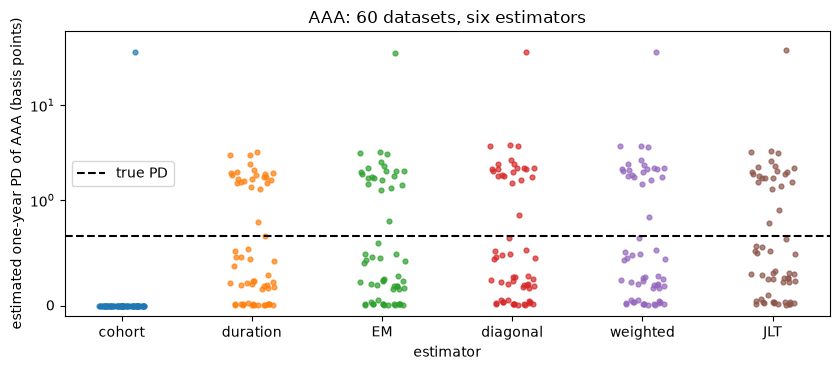

In [4]:
# Draw the 60 AAA estimates of every estimator beside the true PD
fig, ax = plt.subplots(figsize=(8.5, 3.8))
jitter = np.random.default_rng(1).uniform(-0.18, 0.18, size=60)
for k, name in enumerate(names):
    ax.scatter(k + jitter, 1e4 * estimates[name][:, 0], s=12, alpha=0.7)
ax.axhline(1e4 * truth[0], color="black", linestyle="--", label="true PD")
ax.set_yscale("symlog", linthresh=1.0)
ax.set_ylim(-0.1, 60)
ax.set_xticks(range(len(names)))
ax.set_xticklabels([display[name] for name in names])
ax.set_xlabel("estimator")
ax.set_ylabel("estimated one-year PD of AAA (basis points)")
ax.set_title("AAA: 60 datasets, six estimators")
ax.legend()
fig.tight_layout()
plt.show()

The cohort estimator puts 59 of the 60 datasets at exactly zero and the sixtieth at 36 basis points, about fifty-five times the truth (dashed): all of its error sits in the one dataset where a default happened to occur, since a grade with a PD of 0.7 basis points rarely defaults within a few hundred obligor-years. EM and the three repairs never return exactly zero, but they share that outlier because they start from the same snapshots. The duration estimator shows no such outlier in these datasets: it uses the time spent in each grade and gives a non-zero probability to a transition that was not observed directly. One dataset would hide all of this, which is why the harness summarises many.

The next cell passes the 60 estimates of every grade to the engine's `estimator_performance`, which returns the bias, the RMSE and their Monte Carlo standard errors, and prints the AAA row of each estimator.

In [5]:
# Bias, RMSE and their Monte Carlo errors by grade, from the engine's performance harness
relative = {}
for name in names:
    rows = [estimator_performance(estimates[name][:, g], truth[g]) for g in range(7)]
    relative[name] = {key: np.array([r[key] for r in rows]) / truth for key in ("bias", "rmse", "rmse_mcse")}

header = ["rel. bias", "rel. RMSE", "RMSE se", "zeros", "largest (bp)"]
print(f"{'AAA':10s}" + "".join(f"{h:>15s}" for h in header))
for name in names:
    r = relative[name]
    zeros = float(np.mean(estimates[name][:, 0] == 0))
    largest = 1e4 * estimates[name][:, 0].max()
    values = [r["bias"][0], r["rmse"][0], r["rmse_mcse"][0], zeros, largest]
    print(f"{display[name]:10s}" + "".join(f"{v:15.3f}" for v in values))

AAA             rel. bias      rel. RMSE        RMSE se          zeros   largest (bp)
cohort             -0.077          7.090          3.475          0.983         36.364
duration            0.266          1.402          0.138          0.000          3.204
EM                  1.115          6.951          3.326          0.000         35.252
diagonal            1.301          7.210          3.409          0.000         36.333
weighted            1.278          7.156          3.387          0.000         36.082
JLT                 1.269          7.518          3.615          0.000         38.167


The figure draws the relative RMSE of the six estimators for the seven grades on a logarithmic axis. Its message is where the lines separate.

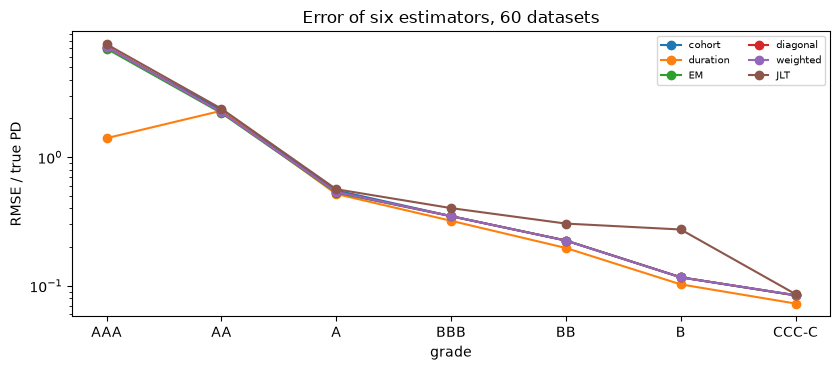

In [6]:
# Draw the relative RMSE of the six estimators by grade from the 60-dataset study
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for name in names:
    ax.plot(range(7), relative[name]["rmse"], marker="o", label=display[name])
ax.set_yscale("log")
ax.set_xticks(range(7))
ax.set_xticklabels(grades)
ax.set_xlabel("grade")
ax.set_ylabel("RMSE / true PD")
ax.set_title("Error of six estimators, 60 datasets")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

From A down the six lines lie close together, with a typical error of about half the PD at A that falls to a tenth of it at B; the repair called JLT drifts away upward from BBB. At AAA and AA the error is a multiple of the PD itself: the duration estimator is five times better at AAA, 1.4 against about 7, but the Monte Carlo standard error printed above is large, and it says so, so the ranking of the top grades is not settled by this small study. The product's own study, with 200 datasets, is the next step. It is read, not rerun, and it tells whether the picture holds with a smaller Monte Carlo error.

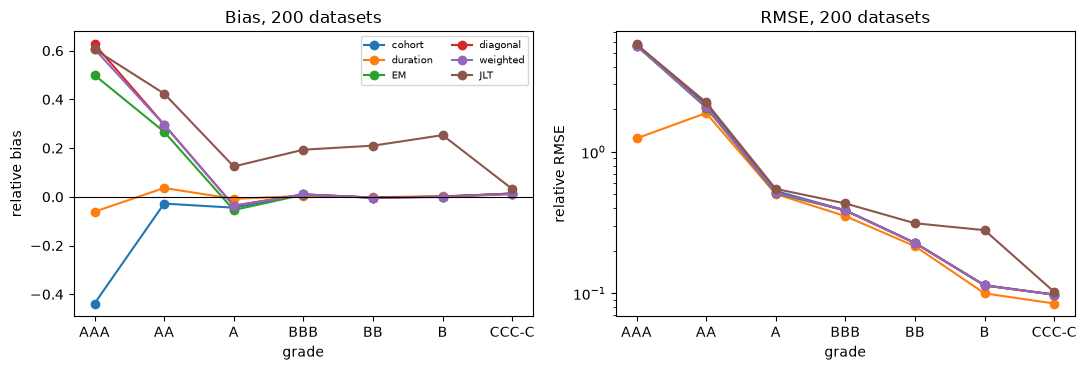

In [7]:
# Draw the relative bias and relative RMSE of the six estimators from the committed 200-dataset study
study = markov["outputs"]["rungs"][0]["estimators"]
truth_200 = np.array(study["cohort"]["truth"])
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
for name in [n for n in names if n in study]:
    left.plot(range(7), np.array(study[name]["bias"]) / truth_200, marker="o", label=display[name])
    right.plot(range(7), np.array(study[name]["rmse"]) / truth_200, marker="o", label=display[name])
left.axhline(0.0, color="black", linewidth=0.8)
right.set_yscale("log")
for panel, label in ((left, "relative bias"), (right, "relative RMSE")):
    panel.set_xticks(range(7))
    panel.set_xticklabels(grades)
    panel.set_xlabel("grade")
    panel.set_ylabel(label)
left.set_title("Bias, 200 datasets")
right.set_title("RMSE, 200 datasets")
left.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

With 200 datasets the left panel separates the estimators that the small study could not. The cohort estimator is biased downwards at AAA, because it returns zero in almost every dataset, and EM and the diagonal and weighted repairs are biased upwards there, because they never return zero. The duration estimator is the only one close to zero bias at AAA. JLT carries a clear positive bias from BBB to B. On the right, the error of every estimator is of the order of the PD at AAA and AA and falls below a tenth of it by CCC-C. What the panels do not show is the real matrix: this is a generator fitted to S&P, with its truth known, not S&P itself.

## State of the art

### What the research found, and what the product does

- **Cohort against duration.** The industry standard estimates the one-year matrix from annual snapshots, the cohort method, removing withdrawals (Anderson and Goodman, 1957; Schuermann and Hanson, 2004). The duration estimator of Lando and Skodeberg (2002) uses every jump and the time in each grade and gives non-zero probabilities for rare transitions. *Product:* both are in the engine; the cohort one runs on the real CEREP tables, the duration one only where paths exist, so the product compares them on simulated paths of known truth (Step 1 above and notebook 02).
- **Repairing the matrix.** The one-year matrix has no exact generator (Israel, Rosenthal and Wei, 2001); the diagonal, weighted and JLT repairs and EM are the practice. *Product:* all four, with the L1 distance and the PD at five years (notebook 03), run live below on the real matrix.
- **Aalen-Johansen** for time-inhomogeneous chains. *Product:* in the engine and in notebook 02; it is run below on the same 60 datasets.
- **Macro-conditioned matrices.** Belkin, Suchower and Forest (1998) condition the matrix on a credit-cycle factor $z$. *Product:* it reads the factor each year implies (`vasicek.implied_factor`, notebook 01) and tests whether the matrix is the same every year (notebook 04); it does not fit a macro-conditioned matrix. The next cell reads the factor of each year from the speculative-grade default rate, which is what such a model would be conditioned on.
- **A reference library.** The research names the `transitionMatrix` package as an independent implementation to cross-check the cohort estimator against. *Product:* the engine's own tests reconcile its cohort estimator with `transitionMatrix` 0.5.1 (RV-415, announced in the release notes of engine 0.8.0): `pooled_cohort` and `cohort` equal the package's cohort estimator element-wise within 1e-12 on a seeded panel with withdrawals. They run where the optional `transitions` extra of the wheel is installed. **This notebook does not rerun them**: `transitionMatrix` is not among its pinned packages, so the equality is reported from the engine and is not counted as a result here. What the notebook shows is the agreement of the product's own estimators, read below.

In [8]:
# The credit-cycle factor of each year from the speculative-grade default rate
labels = out["mobility"]["labels"]
spec = np.array([np.nan if v is None else v for v in out["mobility"]["spec_default_rate"]])
mean_spec = float(np.nanmean(spec))
rho_spec = 0.12  # the Basel minimum corporate correlation, an assumption of this reading
factor = vasicek.implied_factor(spec, mean_spec, rho_spec)
order = np.argsort(factor)
worst = ", ".join(f"{labels[k]} ({factor[k]:.2f})" for k in order[:4])
best = ", ".join(f"{labels[k]} ({factor[k]:.2f})" for k in order[::-1][:4])
print(f"average speculative-grade default rate {mean_spec:.4f}")
print(f"worst years (lowest factor): {worst}")
print(f"best years (highest factor): {best}")
print(f"years with a negative factor: {int((factor < 0).sum())} of {len(factor)}")

average speculative-grade default rate 0.0375
worst years (lowest factor): 2009 (-1.72), 2002 (-1.42), 2001 (-1.35), 2000 (-0.95)
best years (highest factor): 2007 (1.15), 2006 (0.99), 2005 (0.85), 2014 (0.70)
years with a negative factor: 14 of 26


The figure draws the factor of each year; a negative bar is a year worse than the average cycle.

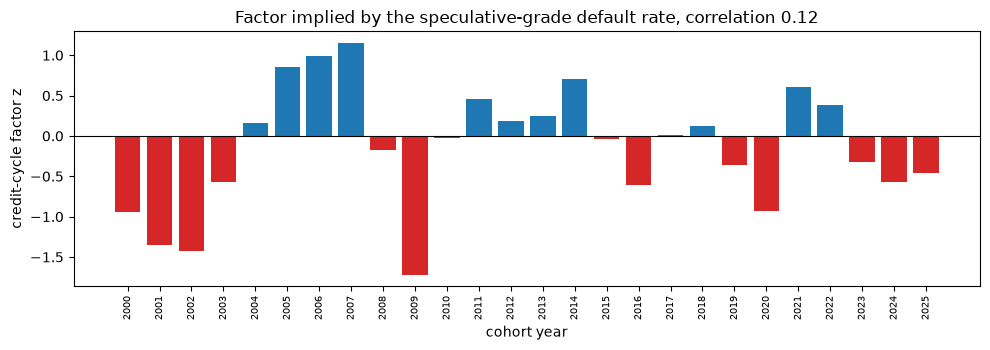

In [9]:
# Draw the credit-cycle factor of each year
fig, ax = plt.subplots(figsize=(10, 3.6))
colours = ["tab:red" if f < 0 else "tab:blue" for f in factor]
ax.bar(range(len(factor)), factor, color=colours)
ax.axhline(0.0, color="black", linewidth=0.8)
ax.set_xticks(range(len(factor)))
ax.set_xticklabels(labels, rotation=90, fontsize=7)
ax.set_xlabel("cohort year")
ax.set_ylabel("credit-cycle factor z")
ax.set_title("Factor implied by the speculative-grade default rate, correlation 0.12")
fig.tight_layout()
plt.show()

The worst years come in two clusters, the dot-com bust of 2000 to 2002 and the 2009 crisis, with 2009 the lowest, and the years between them are positive. Fourteen of the 26 years are below the average cycle, close to half, as a factor centred on the mean should give. A macro-conditioned matrix would use this one number per year to move the whole matrix. The product reads the factor and tests whether the matrix is stable across years (notebook 04), but does not fit the conditioned matrix, and the figure alone does not tell how much each grade's migration would move with the factor.

In [10]:
# Aalen-Johansen on the same 60 datasets: the non-parametric estimate of the one-year matrix
estimates["aalen_johansen"] = np.full((60, 7), np.nan)
for i, child in enumerate(np.random.SeedSequence(20261021).spawn(60)):
    data = generator.draw(np.random.default_rng(child))
    matrix = estimators.aalen_johansen(data["segments"], 8, 0.0, 1.0)["matrix"]
    estimates["aalen_johansen"][i] = np.array(matrix)[:7, -1]
rows = [estimator_performance(estimates["aalen_johansen"][:, g], truth[g]) for g in range(7)]
keys = ("bias", "rmse", "rmse_mcse")
relative["aalen_johansen"] = {key: np.array([r[key] for r in rows]) / truth for key in keys}
aj = relative["aalen_johansen"]
print("Aalen-Johansen, AAA: relative bias", round(aj["bias"][0], 3), "| relative RMSE", round(aj["rmse"][0], 3))
print("Aalen-Johansen, CCC-C: relative bias", round(aj["bias"][6], 3), "| relative RMSE", round(aj["rmse"][6], 3))
others = [round(relative[name]["rmse"][6], 3) for name in ("cohort", "duration")]
print("cohort and duration, CCC-C, relative RMSE:", others)

Aalen-Johansen, AAA: relative bias -0.046 | relative RMSE 2.313
Aalen-Johansen, CCC-C: relative bias 0.0 | relative RMSE 0.202
cohort and duration, CCC-C, relative RMSE: [np.float64(0.084), np.float64(0.073)]


The figure draws its relative RMSE by grade with the cohort and duration estimators of the same datasets.

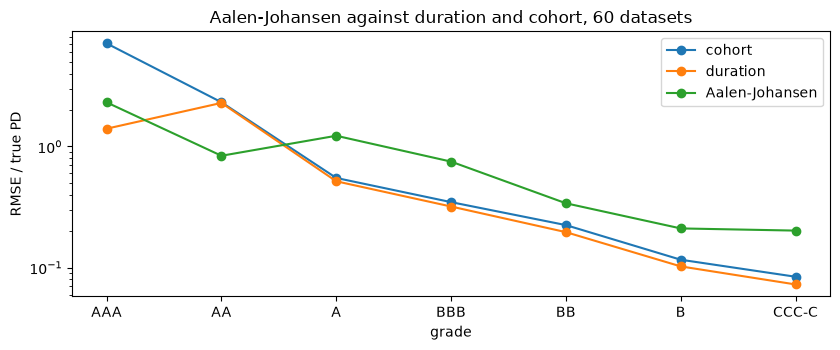

In [11]:
# Draw the relative RMSE of Aalen-Johansen, duration and cohort by grade
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for name in ("cohort", "duration", "aalen_johansen"):
    ax.plot(range(7), relative[name]["rmse"], marker="o", label=display[name])
ax.set_yscale("log")
ax.set_xticks(range(7))
ax.set_xticklabels(grades)
ax.set_xlabel("grade")
ax.set_ylabel("RMSE / true PD")
ax.set_title("Aalen-Johansen against duration and cohort, 60 datasets")
ax.legend()
fig.tight_layout()
plt.show()

Aalen-Johansen sits between the other two at AAA and above both of them from A downwards, by a factor of two to three at BBB and at CCC-C. The reason is in what it estimates. It gives the one-year matrix from the jumps of the first year alone, a non-parametric estimate that does not assume the chain is the same every year, whereas the cohort and duration estimators pool five years because the generator behind the data is time-homogeneous. Here the truth is homogeneous, so pooling is right and Aalen-Johansen pays for not assuming it; where the matrix does change from year to year, which notebook 04 tests on S&P, the pooled estimators would pay in bias instead. The dip at AA is inside the Monte Carlo error of 60 datasets in a thin grade and is not a ranking.

Now the estimators on the real S&P matrix. The next cell rebuilds the pooled matrix from the 26 cohorts' counts and withdrawals, fits the EM generator to the 26 annual tables, derives the diagonal, weighted and JLT generators from the pooled matrix, and takes the one-year and five-year PD of each. The cohort estimator at five years is the pooled matrix to the fifth power, which is what a Markov reading gives without a generator.

In [12]:
# One-year and five-year PD of each estimator on the real S&P matrix
tables = [np.vstack([np.array(c["counts"], dtype=float), np.zeros(8)]) for c in out["cohorts"]]
withdrawn = [np.append(np.array(c["withdrawn"], dtype=float), 0.0) for c in out["cohorts"]]
pooled_real = estimators.pooled_cohort(tables, withdrawn)["matrix"]
generators = {"em": em.em_generator([{"counts": t, "dt": 1.0} for t in tables])["generator"]}
for repair in ("diagonal", "weighted", "jlt"):
    generators[repair] = embedding.generator(pooled_real, method=repair)["generator"]

one_year = {"cohort": pooled_real[:7, 7]}
five_year = {"cohort": np.linalg.matrix_power(pooled_real, 5)[:7, 7]}
for name, q in generators.items():
    one_year[name] = expm(q)[:7, 7]
    five_year[name] = expm(5 * q)[:7, 7]

shown = (0, 5, 6)
heads = [f"{grades[g]} {span}" for span in ("1y", "5y") for g in shown]
print(f"{'PD (%)':10s}" + "".join(f"{h:>10s}" for h in heads))
for name in five_year:
    cells = [100 * table[name][g] for table in (one_year, five_year) for g in shown]
    print(f"{display[name]:10s}" + "".join(f"{c:10.4f}" for c in cells))

PD (%)        AAA 1y      B 1y  CCC-C 1y    AAA 5y      B 5y  CCC-C 5y
cohort        0.0000    1.1731    8.0675    0.1025    8.2143   25.2981
EM            0.0066    1.1731    8.0618    0.1225    8.2142   25.2657
diagonal      0.0069    1.1727    8.0543    0.1270    8.1917   25.1454
weighted      0.0068    1.1709    8.0190    0.1263    8.1758   25.0877
JLT           0.0073    1.4664    8.2170    0.1379    9.0631   26.1829


The figure draws the five-year PD of AAA, B and CCC-C under each estimator, one panel per grade, so that the spread between estimators can be compared with the PD itself.

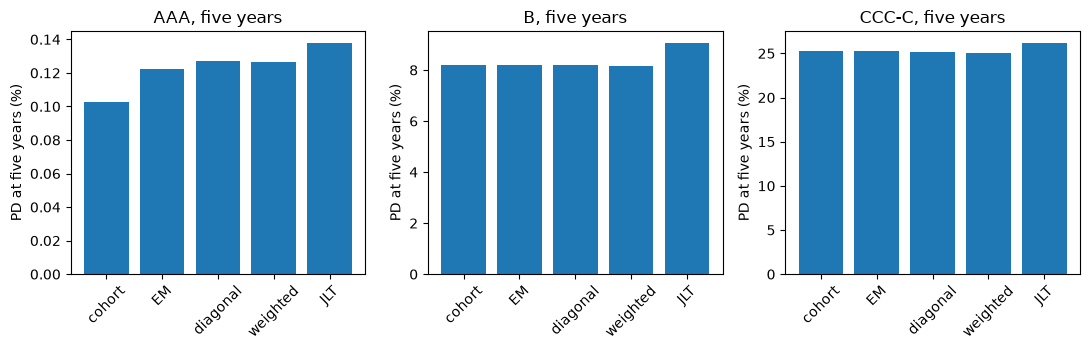

In [13]:
# Draw the five-year PD of three grades under each estimator
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, g in zip(axes, shown):
    ax.bar(range(len(five_year)), [100 * five_year[name][g] for name in five_year], color="tab:blue")
    ax.set_xticks(range(len(five_year)))
    ax.set_xticklabels([display[name] for name in five_year], rotation=45)
    ax.set_title(f"{grades[g]}, five years")
    ax.set_ylabel("PD at five years (%)")
fig.tight_layout()
plt.show()

For B and CCC-C the five bars of the cohort power, EM, diagonal and weighted are almost the same height, within a fraction of a point, and JLT stands about one point above them: the estimators agree where data are plentiful, and the repair that takes the logarithm of the diagonal is the outlier. For AAA the bars are of the order of a tenth of a percent and differ by tens of per cent of themselves, the cohort power being the lowest, as the known-truth study predicts for a grade with a handful of defaults. The figure compares the product's own estimators with one another. It is not a reconciliation with an outside library, and it cannot say which estimator is right on the real matrix, because the real truth is unknown.

## Results

**Answer:** For the best grades the estimator to read is the duration one, and on S&P's real matrix the choice matters little except at AAA and for JLT. On data of known truth the duration estimator has a relative RMSE of 1.402 at AAA and a largest estimate of 3.2 basis points, while the cohort estimator has 7.090, returns exactly zero in 0.98 of the datasets and reaches 36.4 basis points in the one dataset with a default; EM and the three repairs have an error of about the same size. On the real matrix the five-year PD of CCC-C is 25.2981, 25.2657, 25.1454 and 25.0877 per cent by the cohort power, EM and the diagonal and weighted repairs, against 26.1829 by JLT, and that of AAA runs from 0.1025 to 0.1379.

- **Duration against cohort, on a known truth.** At AAA the 60-dataset study gives the cohort estimator a relative bias of -0.077 and an RMSE of 7.090 (Monte Carlo error 3.475), and the duration estimator 0.266 and 1.402 (0.138). The error of the cohort estimator sits in one dataset, so its Monte Carlo error is as large as the number. The committed 200-dataset study shows the same at lower noise: the relative bias at AAA is -0.44 for the cohort estimator and -0.06 for duration, +0.50 for EM and about +0.6 for the diagonal, weighted and JLT estimators. From A to CCC-C the estimators are close, and JLT carries a bias of 0.19 to 0.25 from BBB to B.
- **EM and the repairs add nothing at the thin end.** They read the same annual snapshots as the cohort estimator and have its error at AAA (relative RMSE 6.951 for EM, 7.210 and 7.156 for the repairs and 7.518 for JLT) with a positive bias of 1.1 to 1.3 in this study, because they never return exactly zero. A bank that holds only the agency's annual tables has these and not the duration estimator, which needs rating histories.
- **Aalen-Johansen.** Its relative RMSE is 2.313 at AAA and 0.202 at CCC-C, against 7.090 and 0.084 for the cohort estimator and 1.402 and 0.073 for duration: it pays for estimating one year from that year alone.
- **Macro conditioning.** The speculative-grade default rate averages 0.0375; with an assumed correlation of 0.12 the lowest factors are 2009 (-1.72), 2002 (-1.42), 2001 (-1.35) and 2000 (-0.95), the highest 2007 (1.15), 2006 (0.99), 2005 (0.85) and 2014 (0.70), and 14 of the 26 years are negative. The product reads this factor and tests the stability of the matrix; it does not fit a conditioned matrix.
- **On the real matrix the estimators agree where data are plentiful.** The one-year PD of B is 1.1731, 1.1731, 1.1727 and 1.1709 per cent for the cohort matrix, EM and the two repairs and 1.4664 for JLT; that of CCC-C is 8.0675, 8.0618, 8.0543 and 8.0190 against 8.2170. At five years the PD of B is 8.2143, 8.2142, 8.1917 and 8.1758 against 9.0631 for JLT.
- **The reference library.** The equality of the cohort estimator with `transitionMatrix` is an engine test (RV-415) that this notebook does not rerun and does not count; the agreement above is the product's own estimators against each other.

What this notebook does not show: the effect of the default definition and of withdrawals on these PDs, and the coverage of intervals on thin grades (notebook 10).

## Summary

- The cohort estimator cannot see the AAA PD from annual snapshots, and neither can EM or the matrix repairs; the duration estimator can, where paths exist, with an error of the order of the PD itself.
- Where data are plentiful the estimators agree to a fraction of a point at five years; JLT stays about a point above.
- Estimators are compared by bias and RMSE with their Monte Carlo errors, on known truth; a small study with the harness shows how the numbers arise, and a larger one firms them up.
- The product reads the credit-cycle factor and tests the stability of the matrix but fits no conditioned matrix, and runs no reconciliation with a reference library.

**What to try next.** Raise the draws of the study of Step 1 to 200 and see the standard errors fall; then read notebook 09.

## References

- ESMA, CEREP publication of credit rating agency ratings and transitions. https://registers.esma.europa.eu/cerep-publication/
- Anderson, T. W. and Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1). https://doi.org/10.1214/aoms/1177707039
- Israel, R. B., Rosenthal, J. S. and Wei, J. Z. (2001), Finding generators for Markov chains via empirical transition matrices, Mathematical Finance 11(2). https://doi.org/10.1111/1467-9965.00114
- Schuermann, T. and Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Lando, D. and Skodeberg, T. M. (2002), Analyzing rating transitions and rating drift with continuous observations, Journal of Banking and Finance 26(2-3), doi 10.1016/S0378-4266(01)00228-X.
- Jarrow, R. A., Lando, D. and Turnbull, S. M. (1997), the approximation of equation (3) and Lemma 1, as cited by Israel, Rosenthal and Wei (2001) and in the engine's documentation.
- Belkin, B., Suchower, S. and Forest, L. R. (1998), A one-parameter representation of credit risk and transition matrices, CreditMetrics Monitor, third quarter.
- Bladt, M. and Sørensen, M. (2005), Statistical inference for discretely observed Markov jump processes, Journal of the Royal Statistical Society B 67(3), 395-410.
- Smith, A. and dos Reis, G. (2018), Quantitative Finance, doi 10.1080/14697688.2017.1383627, for the EM generator.
- Morris, T. P., White, I. R. and Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11), doi 10.1002/sim.8086.